In [71]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, classification_report


In [72]:
df = pd.read_csv("../output/features/merged_results.csv")
df.drop(columns=["coordinateUncertaintyInMeters", "gbifID"], inplace=True)
df.dropna(inplace=True)

In [73]:
species_counts = df["species"].value_counts()
species_to_keep = species_counts[(species_counts > 100) & (species_counts < 1000)].index
df = df[df["species"].isin(species_to_keep)]
print(df.shape)
df["species"].value_counts()

(7502, 29)


species
Sibbaldia procumbens        975
Carex myosuroides           843
Carex parviflora            822
Petrocallis pyrenaica       673
Astragalus alpinus          630
Kalmia procumbens           544
Erigeron alpinus            534
Juncus triglumis            454
Comastoma tenellum          434
Draba dubia                 400
Astragalus penduliflorus    324
Carex rupestris             273
Gentiana orbicularis        254
Coronilla vaginalis         201
Arctostaphylos alpinus      141
Name: count, dtype: int64

In [74]:
cords_df = df[["species", "decimalLatitude", "decimalLongitude"]]
df = df.drop(columns=["decimalLatitude", "decimalLongitude"])
print(df.shape)
df.columns

(7502, 27)


Index(['species', 'elevation', 'slope', 'aspect', 'TPI', 'TRI', 'roughness',
       'flowdir', 'wc2.1_30s_bio_1', 'wc2.1_30s_bio_10', 'wc2.1_30s_bio_11',
       'wc2.1_30s_bio_12', 'wc2.1_30s_bio_13', 'wc2.1_30s_bio_14',
       'wc2.1_30s_bio_15', 'wc2.1_30s_bio_16', 'wc2.1_30s_bio_17',
       'wc2.1_30s_bio_18', 'wc2.1_30s_bio_19', 'wc2.1_30s_bio_2',
       'wc2.1_30s_bio_3', 'wc2.1_30s_bio_4', 'wc2.1_30s_bio_5',
       'wc2.1_30s_bio_6', 'wc2.1_30s_bio_7', 'wc2.1_30s_bio_8',
       'wc2.1_30s_bio_9'],
      dtype='str')

In [75]:
species_map = {species: idx for idx, species in enumerate(df["species"].unique())}
species_map

{'Comastoma tenellum': 0,
 'Arctostaphylos alpinus': 1,
 'Draba dubia': 2,
 'Carex myosuroides': 3,
 'Erigeron alpinus': 4,
 'Astragalus alpinus': 5,
 'Coronilla vaginalis': 6,
 'Kalmia procumbens': 7,
 'Astragalus penduliflorus': 8,
 'Juncus triglumis': 9,
 'Carex rupestris': 10,
 'Carex parviflora': 11,
 'Petrocallis pyrenaica': 12,
 'Sibbaldia procumbens': 13,
 'Gentiana orbicularis': 14}

In [76]:
df["species"] = df["species"].map(species_map)
print(df["species"].unique())

[ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14]


In [77]:
X = df.drop(columns=["species"])
y = df["species"]

(array([434., 141., 400., 843., 534., 630., 201., 544., 324., 454., 273.,
        822., 673., 975., 254.]),
 array([-0.5,  0.5,  1.5,  2.5,  3.5,  4.5,  5.5,  6.5,  7.5,  8.5,  9.5,
        10.5, 11.5, 12.5, 13.5, 14.5]),
 <BarContainer object of 15 artists>)

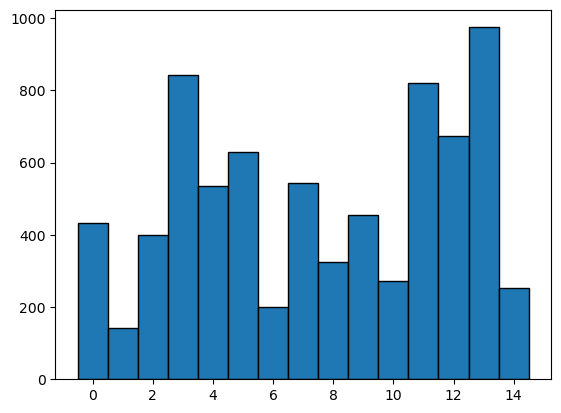

In [78]:
plt.hist(y, bins=np.arange(len(species_map) + 1) - 0.5, edgecolor="black")

In [79]:
scalaer = StandardScaler()
X_scaled = scalaer.fit_transform(X)
print(X_scaled.shape)

(7502, 26)


In [80]:
pca = PCA(n_components=20)
X_pca = pca.fit_transform(X_scaled)

Explained variance: [3.12766103e-01 2.20806321e-01 1.45705258e-01 1.10281433e-01
 4.96958367e-02 4.65952762e-02 3.46863930e-02 2.96373220e-02
 2.81056333e-02 9.50558772e-03 2.65668740e-03 2.39217807e-03
 2.00727960e-03 1.52039168e-03 1.20240136e-03 7.63508721e-04
 5.62967834e-04 4.47851735e-04 2.33116753e-04 1.94437942e-04]
Cumulative: [0.3127661  0.53357242 0.67927768 0.78955912 0.83925495 0.88585023
 0.92053662 0.95017394 0.97827958 0.98778516 0.99044185 0.99283403
 0.99484131 0.9963617  0.9975641  0.99832761 0.99889058 0.99933843
 0.99957155 0.99976599]


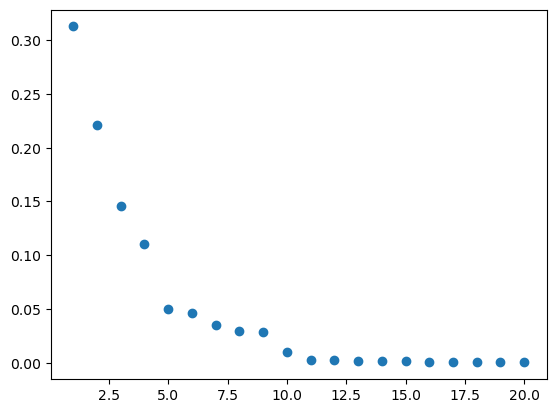

In [81]:
print("Explained variance:", pca.explained_variance_ratio_)
print("Cumulative:", np.cumsum(pca.explained_variance_ratio_))
plt.scatter(range(1, len(pca.explained_variance_ratio_) + 1), pca.explained_variance_ratio_, marker="o")

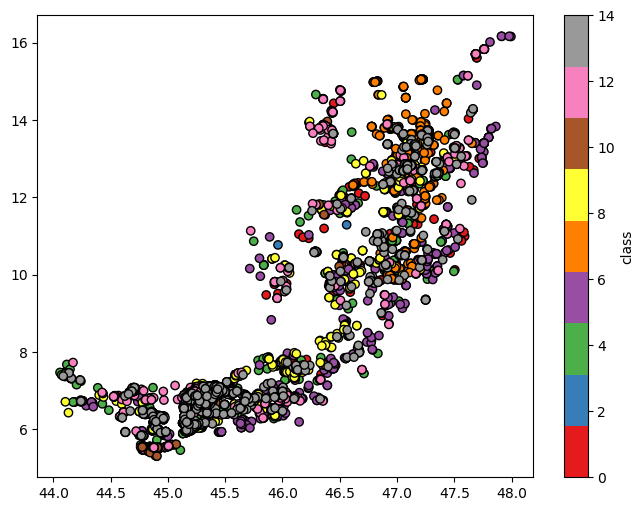

In [82]:
plt.figure(figsize=(8,6))
plt.scatter(cords_df.decimalLatitude, cords_df.decimalLongitude, c=y, cmap='Set1', edgecolor='k')
plt.colorbar(label="class")
plt.show()

Zrobię takie kwadraciki 2 wymiarowe z (x, y). Żeby jakoś te stanowiska pogrupować. I później pewnie każde stanowisko sobie przedstawię jako binarny wektor 16 wymiarowy (liczba gatunków).
Te gridy są trochę mało "geograficzne". Pewnie lepiej pogrupować te stanowiska jakimś dbscan po lokalizacji.

Wtedy będziemy mieć mniej rekordów. I będziemy na ich podstawie przewidywać 16 wartości 1/0.

Klastrujemy bez normalizacji, bo równoleżnik południkowi nie równy i to dobrze, ale użyję metryki Haversina (przy tym naszym na modmolu tak robiłem też).

In [83]:
res = 0.05 # 100 metrów chyba
cords_df["lat_bin"] = (cords_df["decimalLatitude"] // res)
cords_df["lon_bin"] = (cords_df["decimalLongitude"] // res)
cords_df["grid_cell"] = cords_df["lat_bin"].astype(str) + "_" + cords_df["lon_bin"].astype(str)
cords_df.head()

,species,decimalLatitude,decimalLongitude,lat_bin,lon_bin,grid_cell
3548,Comastoma tenellum,45.415268,7.028685,908.0,140.0,908.0_140.0
3549,Comastoma tenellum,47.120875,12.820054,942.0,256.0,942.0_256.0
3550,Comastoma tenellum,47.159256,13.382659,943.0,267.0,943.0_267.0
3551,Comastoma tenellum,47.057584,12.858508,941.0,257.0,941.0_257.0
3552,Comastoma tenellum,47.120875,12.820054,942.0,256.0,942.0_256.0


In [84]:
grid_species_counts = cords_df.groupby(["grid_cell", "species"]).size().unstack(fill_value=0)
grid_species_counts = (grid_species_counts > 0).astype(int)
print(grid_species_counts.shape)
grid_species_counts.head()

(1074, 15)


species,Arctostaphylos alpinus,Astragalus alpinus,Astragalus penduliflorus,Carex myosuroides,Carex parviflora,Carex rupestris,Comastoma tenellum,Coronilla vaginalis,Draba dubia,Erigeron alpinus,Gentiana orbicularis,Juncus triglumis,Kalmia procumbens,Petrocallis pyrenaica,Sibbaldia procumbens
grid_cell,,,,,,,,,,,,,,,
881.0_147.0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1
881.0_148.0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0
881.0_149.0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0
882.0_128.0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0
882.0_134.0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0


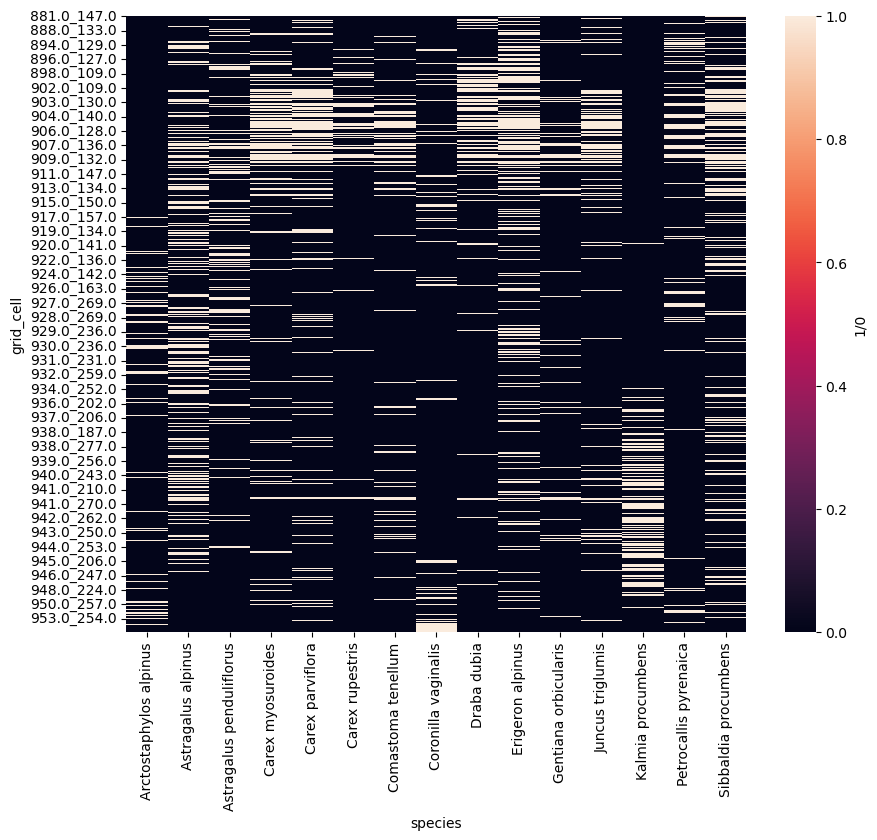

In [85]:
plt.figure(figsize=(10,8))
sns.heatmap(grid_species_counts, cbar_kws={'label': '1/0'})
plt.show()

tutaj tak po prostu naiwnie w krateczkę. Poniżej dbscan

In [86]:
from sklearn.cluster import DBSCAN
import numpy as np

coords_rad = np.radians(cords_df[["decimalLatitude", "decimalLongitude"]].values)

epsilon_km = 0.5
db = DBSCAN(
    eps=epsilon_km / 6371.0,
    min_samples=1,
    algorithm='ball_tree',
    metric='haversine'
)
cords_df["site"] = db.fit_predict(coords_rad)

print(f"Liczba stanowisk: {cords_df['site'].nunique()}")

Liczba stanowisk: 2095


In [87]:
df_with_site = pd.DataFrame(X_scaled)
df_with_site.columns = X.columns
df_with_site["site"] = cords_df.site.values

feature_cols = [c for c in X.columns if c != "species"]

# odchylenie, dla każdego stanowiwska, dla każdej cechy
within_std = df_with_site.groupby("site")[feature_cols].std()

comparison = pd.DataFrame({
    "within_std_median": within_std.max(),
    #"total_std": df_with_site[feature_cols].std(),
})
#comparison["ratio"] = comparison["within_std_median"] / comparison["total_std"]
comparison.sort_values("within_std_median", ascending=False)


,within_std_median
roughness,2.855170
slope,2.842195
TRI,2.722687
aspect,2.287478
flowdir,2.258971
TPI,2.216992
wc2.1_30s_bio_12,1.117221
wc2.1_30s_bio_14,1.075492
wc2.1_30s_bio_17,1.034645
wc2.1_30s_bio_15,1.029212


To chyba byłaby dobra metryka jakości klastrowania gdybyśmy mieli dużą kompresję. Bo teraz to mamy większość klastrów "zerowych".

Z drugiej strony, być może samo takie odchylenie w ramach danego stanowiska jest ciekawe. Bo to znaczy, że jest tam bardzo zróżnicowany teren, a nie jakaś ładna dolinka albo konsystentne zbocze.

# random forest między gatunkami

In [88]:
df

,species,elevation,slope,aspect,TPI,TRI,roughness,flowdir,wc2.1_30s_bio_1,wc2.1_30s_bio_10,...,wc2.1_30s_bio_18,wc2.1_30s_bio_19,wc2.1_30s_bio_2,wc2.1_30s_bio_3,wc2.1_30s_bio_4,wc2.1_30s_bio_5,wc2.1_30s_bio_6,wc2.1_30s_bio_7,wc2.1_30s_bio_8,wc2.1_30s_bio_9
3548,0,2752,24.266371,118.341355,7.125,73.125,240.0,2,-1.166667,6.900000,...,263,389,5.916667,26.064611,610.924561,12.0,-10.7,22.700001,-6.066667,6.900000
3549,0,2231,17.354172,270.864776,1.500,54.750,160.0,16,-0.383333,6.833333,...,513,281,6.283333,28.691019,586.590027,11.2,-10.7,21.900000,6.833333,-7.083333
3550,0,2374,16.835594,237.734291,29.875,61.125,191.0,8,-0.595833,6.616667,...,559,316,6.625000,29.708521,584.058899,11.2,-11.1,22.299999,6.616667,-7.116667
3551,0,2240,22.452272,182.944046,5.000,66.250,214.0,4,0.370833,7.700000,...,505,262,7.375000,31.926407,596.624817,12.7,-10.4,23.099998,7.700000,-6.483333
3552,0,2231,17.354172,270.864776,1.500,54.750,160.0,16,-0.383333,6.833333,...,513,281,6.283333,28.691019,586.590027,11.2,-10.7,21.900000,6.833333,-7.083333
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
12507,14,2140,12.553673,93.491171,25.500,44.250,169.0,2,0.345833,7.633333,...,557,297,6.975000,30.726873,590.229004,12.3,-10.4,22.700001,7.633333,-6.233333
12508,14,2582,9.493587,118.191308,6.125,33.875,139.0,128,-2.070833,5.016667,...,506,313,5.608334,26.579779,574.022705,9.1,-12.0,21.100000,5.016667,-8.516666
12509,14,2546,28.546902,61.379629,8.875,90.375,289.0,1,-3.379167,3.166667,...,500,318,5.025000,25.769230,541.875793,6.4,-13.1,19.500000,3.166667,-9.650000
12510,14,2581,20.780399,205.490135,23.125,63.875,221.0,8,-1.929167,4.733333,...,510,288,5.625000,27.439024,551.611084,8.5,-12.0,20.500000,4.733333,-8.366667


In [89]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix

X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.2, random_state=42)


rf = RandomForestClassifier(n_estimators=100, random_state=42, class_weight="balanced")
rf.fit(X_train, y_train)
y_pred = rf.predict(X_test)

In [90]:
report = classification_report(y_test, y_pred)
print(report)

              precision    recall  f1-score   support

           0       0.35      0.34      0.35        96
           1       0.47      0.39      0.42        36
           2       0.39      0.51      0.44        67
           3       0.28      0.19      0.23       192
           4       0.38      0.39      0.38       103
           5       0.39      0.48      0.43       124
           6       0.79      0.75      0.77        44
           7       0.66      0.87      0.75        87
           8       0.56      0.63      0.59        67
           9       0.41      0.41      0.41        87
          10       0.18      0.28      0.22        47
          11       0.24      0.19      0.21       159
          12       0.62      0.63      0.63       140
          13       0.56      0.48      0.52       200
          14       0.32      0.42      0.36        52

    accuracy                           0.44      1501
   macro avg       0.44      0.46      0.45      1501
weighted avg       0.43   

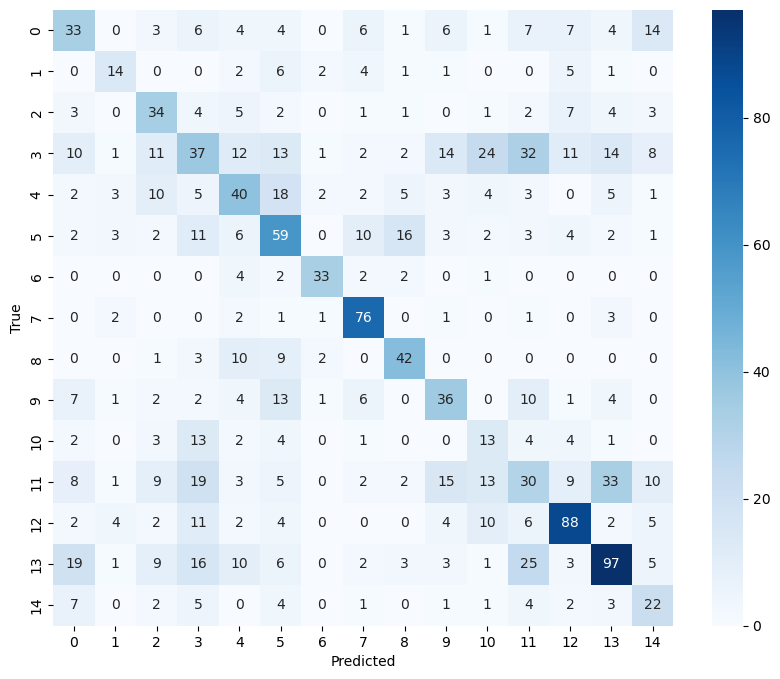

In [91]:
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(10,8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predicted')
plt.ylabel('True')
plt.show()

# KDE

In [93]:
from scipy.stats import gaussian_kde
import itertools

In [94]:
n_grid = 100
pc1 = X_pca[:, 0]
pc2 = X_pca[:, 1]

grid_x = np.linspace(pc1.min(), pc1.max(), n_grid)
grid_y = np.linspace(pc2.min(), pc2.max(), n_grid)
xx, yy = np.meshgrid(grid_x, grid_y)
grid_pts = np.vstack([xx.ravel(), yy.ravel()])

species_kdes = {}
for sp_id, sp_name in enumerate(species_map):
    mask = (y == sp_id).values
    pts = np.vstack([pc1[mask], pc2[mask]])
    kde = gaussian_kde(pts)
    density = kde(grid_pts).reshape(n_grid, n_grid)
    density /= density.sum()
    species_kdes[sp_name] = density

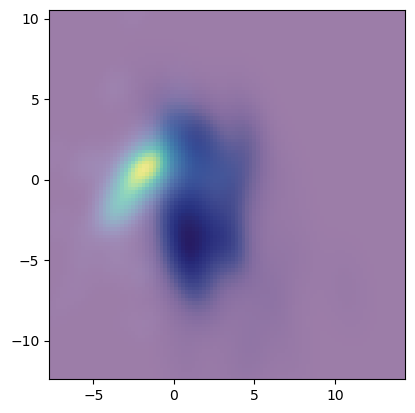

In [131]:
plt.imshow(species_kdes["Comastoma tenellum"], extent=(pc1.min(), pc1.max(), pc2.min(), pc2.max()), origin='lower', cmap='viridis')
plt.imshow(species_kdes["Arctostaphylos alpinus"], extent=(pc1.min(), pc1.max(), pc2.min(), pc2.max()), origin='lower', cmap='Blues', alpha=0.5)